In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

In [2]:
model = joblib.load("../models/random_forest_best.pkl")

In [3]:
spectra = pd.read_csv(
    "../data/processed_spectra.csv",
    index_col=0
)

X = spectra.drop(columns=["Label"])
y = spectra["Label"]

In [4]:
rf = model.named_steps["classifier"]

In [5]:
importances = rf.feature_importances_

importance_df = pd.DataFrame({
    "Wavenumber": X.columns.astype(float),
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(20)

,Wavenumber,Importance
458,1753.7125,0.019042
457,1751.8488,0.015908
455,1748.1214,0.014942
477,1789.1222,0.014016
483,1800.3042,0.013784
460,1757.4398,0.013154
459,1755.5761,0.011598
401,1647.4833,0.011205
475,1785.3948,0.010897
463,1763.0308,0.010894


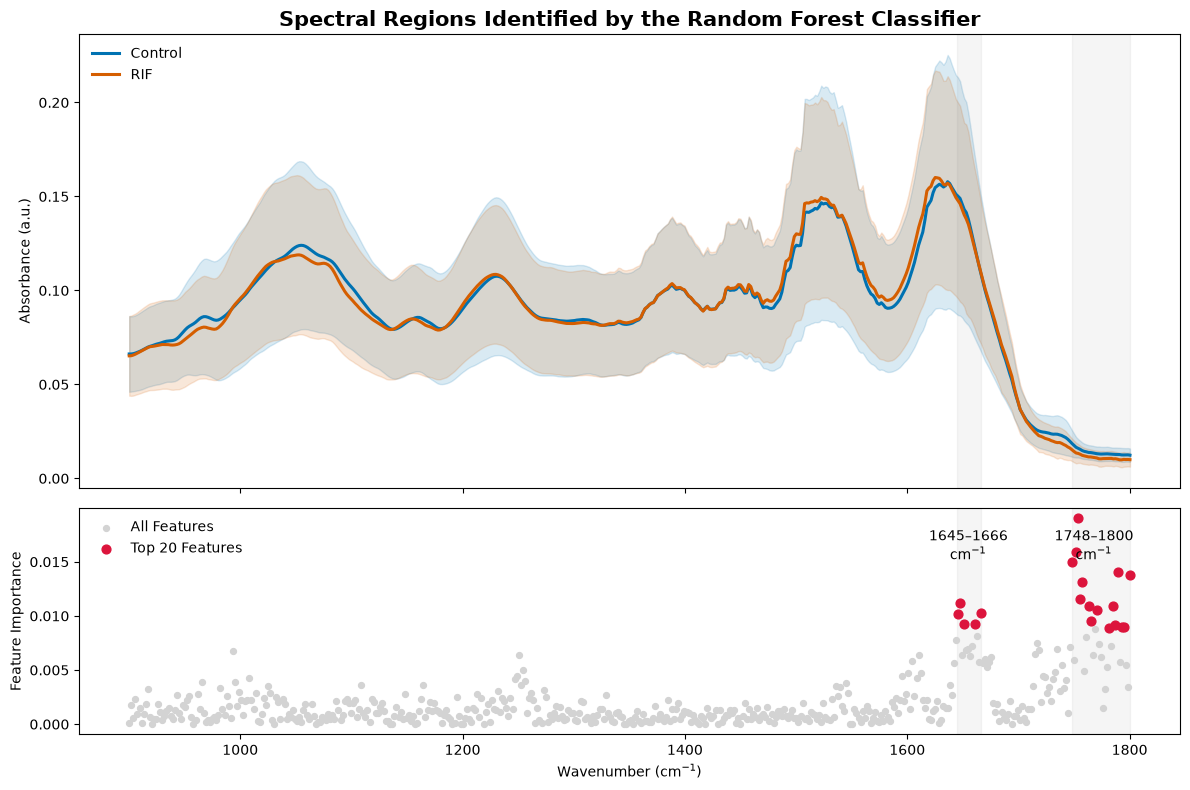

In [6]:

import matplotlib.pyplot as plt

# Load statistics from previous notebook if not already in memory
control = spectra[spectra["Label"] == 0].drop(columns=["Label"])
rif = spectra[spectra["Label"] == 1].drop(columns=["Label"])

control_mean = control.mean(axis=0)
rif_mean = rif.mean(axis=0)

control_std = control.std(axis=0)
rif_std = rif.std(axis=0)

wn = control.columns.astype(float)

top20 = importance_df.head(20)

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12,8),
    sharex=True,
    gridspec_kw={"height_ratios":[2,1]}
)

# ---- Top panel: Mean spectra ----
ax1.plot(wn, control_mean, color="#0072B2", linewidth=2.2, label="Control")
ax1.fill_between(wn,
                 control_mean-control_std,
                 control_mean+control_std,
                 color="#0072B2",
                 alpha=0.15)

ax1.plot(wn, rif_mean, color="#D55E00", linewidth=2.2, label="RIF")
ax1.fill_between(wn,
                 rif_mean-rif_std,
                 rif_mean+rif_std,
                 color="#D55E00",
                 alpha=0.15)

important_regions = [(1748,1800),(1645,1666)]

for start,end in important_regions:
    ax1.axvspan(start,end,color="gray",alpha=0.08)
    ax2.axvspan(start,end,color="gray",alpha=0.08)

ax1.set_ylabel("Absorbance (a.u.)")
ax1.set_title("Spectral Regions Identified by the Random Forest Classifier",
              fontsize=15,fontweight="bold")
ax1.legend(frameon=False)
ax1.grid(False)

# ---- Bottom panel: Feature importance ----
ax2.scatter(importance_df["Wavenumber"],
            importance_df["Importance"],
            color="lightgray",
            s=18,
            label="All Features")

ax2.scatter(top20["Wavenumber"],
            top20["Importance"],
            color="crimson",
            s=40,
            label="Top 20 Features")

ymax = importance_df["Importance"].max()

ax2.text(1768, ymax*0.95, "1748–1800\ncm$^{-1}$",
         ha="center", va="top", fontsize=10)

ax2.text(1655, ymax*0.95, "1645–1666\ncm$^{-1}$",
         ha="center", va="top", fontsize=10)

ax2.set_ylabel("Feature Importance")
ax2.set_xlabel("Wavenumber (cm$^{-1}$)")
ax2.legend(frameon=False)
ax2.grid(False)

ax1.invert_xaxis()
ax2.invert_xaxis()

plt.tight_layout()

plt.savefig("../figures/Figure7_SpectralInterpretation.png",
            dpi=300,
            bbox_inches="tight")

plt.show()


In [7]:
from interpretation import group_adjacent_peaks

regions = group_adjacent_peaks(
    importance_df,
    threshold=0.008
)

regions

,Start,End,Mean Importance,Max Importance,Peaks
0,1645.6197,1651.2107,0.010232,0.011205,3
1,1660.5290,1666.1200,0.009225,0.010301,3
2,1748.1214,1770.4855,0.012252,0.019042,10
3,1781.6675,1800.3042,0.010684,0.014016,7


In [8]:
regions.to_csv(
    "../results/top_regions.csv",
    index=False
)